# 57 · Actor–Critic와 GAE: 가치 타깃과 정책 기울기를 분리하기

📎 **이번 질문** · 정책이 고른 행동을 얼마나 좋았다고 평가할까요? 아직 받지 않은 보상은 critic으로 어디까지 채울까요?

actor는 행동 확률을 배우고 critic은 그 정책의 기대 return을 배웁니다. 둘을 연결하는 advantage를 고정한 뒤 서로 다른 손실로 갱신합니다. GAE의 종료·수집 경계를 확인하고, 작은 환경의 모든 경로를 열거해 편향과 분산을 실제 미분과 대조합니다.

- 준비물: [13 계산 그래프](../02_연결/13_autodiff.ipynb), [53 MC·TD](53_mc_td.ipynb), 56 REINFORCE. [전체 학습 경로](../../docs/CURRICULUM.md)에서 정책 기울기 유도를 먼저 확인합니다.
- 도착점: actor·critic·advantage, 두 마스크의 GAE, 고정 타깃 전체 미분, 새 rollout을 이용한 실제 학습과 평가.
- 54번의 시작보상0인4상태 환경을 재사용합니다. 56번의 시작 보상 안전+.2/위험−.1 변경은 여기서는 사용하지 않습니다. 최적 시작 가치는1.8입니다.
- actor는 one-hot3→softmax2의6개 파라미터, critic은 one-hot3→선형값의3개 파라미터입니다. 모든 비종료 상태를 정확히 표현할 수 있는 작은 표 기반 선형 모델이며, 원 GAE 논문의 연속 제어·큰 신경망을 재현하지 않습니다.

### 읽는 법

| 표시 | 뜻 | 읽는 방법 |
|---|---|---|
| 🔑 핵심 | 수식·구현 | 어떤 경로를 고정하고 미분하는지 적습니다 |
| 🔍 확인 | 그림·검산 | 타깃 편향과 학습 결과를 구분합니다 |
| 📎 참고 | 용어·코드 | 경계와 축 규약을 확인합니다 |
| ✏️ 연습 | 한두 줄 구현 | 독립 손계산과 비교합니다 |

**이 노트북에서 반드시 가져갈 세 가지**

1. actor의 확률과 critic의 값은 별도 모델입니다. advantage·critic return은 업데이트 전에 고정합니다.
2. terminated는 다음 가치 bootstrap을, boundary는 다른 수집 경로의 잔차 연결을 막습니다.
3. λ를 바꾸면 잘못된 critic을 사용하는 정도와 경로 기울기의 분산이 바뀝니다. 유한 학습 성과의 우열은 별도 관측입니다.

| 기호 | shape | 뜻 |
|---|---|---|
| states,actions,rewards | `(B,T)` | B개 경로의 T개 전이 |
| X,θ,w | `(N,3),(3,2),(3,)` | 펼친 one-hot 상태·actor·critic 파라미터 |
| δ,A,Rλ | `(B,T)` | TD잔차·GAE advantage·critic 고정 타깃 |
| terminated,boundary | `(B,T)` | 진짜 종료·경로 연결 중단 표시 |

실제 학습은 T=2·N=2B이고 padding은 없습니다. [그림 보조 코드](../../src/utils/actor_critic_plots.py)

In [1]:
# 준비 셀: 수치계산·개념 그림·연습 검사 도구입니다.
import sys
from pathlib import Path
import numpy as np
project_root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'src/utils/plotting.py').is_file())
if str(project_root) not in sys.path:
    sys.path.insert(0,str(project_root))
from src.utils import setup_plots, run_check
from src.utils.actor_critic_plots import (
    plot_actor_critic_values, plot_gae_masks, plot_gae_mixture, plot_gae_bias_variance,
    plot_ac_gradients, plot_ac_protocol, plot_ac_learning, plot_ac_final,
)
setup_plots()
print('별도 actor6개·critic3개 · 할인목적 J=E[R1+.9R2]')

별도 actor6개·critic3개 · 할인목적 J=E[R1+.9R2]


## 🔑 1. actor의 행동과 critic의 기대값을 연결합니다

**이 절에서 가져갈 것:** advantage는 선택 행동의 Q에서 그 상태의 V를 뺀 값이며, 정책 평균에서는0입니다.

시작0에서 행동0은 안전2, 행동1은 위험1로 갑니다. 시작의 보상은0입니다. 안전 상태는 두 행동 모두 .7, 위험 상태는 좋은 행동0이2·실수 행동1이−14를 받고 종료3으로 갑니다. γ=.9입니다.

> **용어**
>
> - **actor**는 행동 확률 π를 내는 모델입니다. 이 단원은 `π=softmax(Xθ)`를 씁니다.
> - **critic**은 현재 정책의 상태 가치 V를 추정하는 모델입니다. 이 단원은 `V=Xw`를 씁니다.
> - **advantage**는 같은 상태의 평균 행동보다 얼마나 좋거나 나쁜지를 나타내는 값 $A^\pi(s,a)=Q^\pi(s,a)-V^\pi(s)$입니다. 실제 학습에서는 이를 표본으로 추정합니다.

$$V^\pi(s)=\sum_a\pi(a|s)Q^\pi(s,a),\qquad \sum_a\pi(a|s)A^\pi(s,a)=0.$$

정책이 시작 `(.8,.2)`, 위험 `(.9,.1)`, 안전 `(.5,.5)`라면 위험 상태 V=.4, 안전 V=.7, 시작 Q=(.63,.36), 시작 V=.576입니다. 따라서 시작 advantage는 (.054,−.216)입니다. 아직 학습한 critic이 아니라 작은 환경의 정확 기준을 먼저 계산합니다.

> **코드** · `np.eye(3)`은 세 비종료 상태의 one-hot 행들입니다. `keepdims=True`로 행동 축을 길이1로 남겨 안정적인 softmax를 계산합니다. `np.log(policy)`는 각 상태의 확률을 그대로 재현하는 logits 한 가지입니다.

In [2]:
gamma = 0.9
example_policy = np.array([[.8,.2],[.9,.1],[.5,.5]])
example_theta = np.log(example_policy)
example_q = gamma*np.array([.7,.9*2+.1*(-14)])
example_value_loop = 0.0
for action in range(2):
    example_value_loop += example_policy[0,action]*example_q[action]
example_value = np.sum(example_policy[0]*example_q)
example_advantage = example_q-example_value

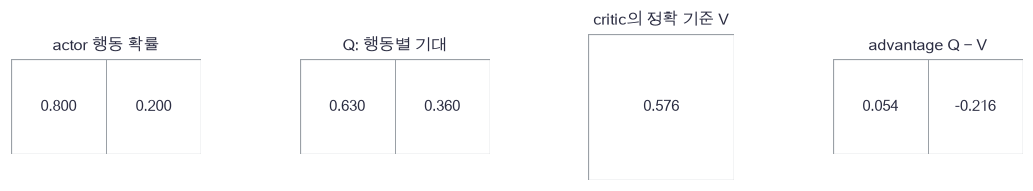

In [3]:
plot_actor_critic_values(example_policy[0], example_q, np.array([example_value]), example_advantage)

🔍 **확인** · 위험 행동의 advantage는 음수지만 그 행동의 Q 자체는 양수입니다. advantage는 상태의 평균과 비교한 상대값입니다. 확률을 곱해 더한 advantage가0이라는 항등식이 action에 무관한 baseline을 뺄 수 있는 이유와 연결됩니다.

In [4]:
def ac_policy(theta,x):
    """X:(N,3), theta:(3,2)에서 행동확률·안정적인 log확률:(N,2)을 반환합니다."""
    logits = x@theta
    shifted = logits-logits.max(axis=1,keepdims=True)
    log_probabilities = shifted-np.log(np.exp(shifted).sum(axis=1,keepdims=True))
    return np.exp(log_probabilities),log_probabilities

In [5]:
def ac_exact(theta,gamma=0.9):
    """54번 시작보상0 환경의 정확 J·전체 정책 미분·상태 가치:(3,)를 직접 계산합니다."""
    policy,log_probabilities = ac_policy(theta,np.eye(3))
    risky = policy[1]@np.array([2.0,-14.0])
    branches = gamma*np.array([0.7,risky])
    value = policy[0]@branches
    gradient = np.zeros_like(theta)
    gradient[0] = policy[0]*(branches-value)
    gradient[1] = gamma*policy[0,1]*policy[1]*(np.array([2.0,-14.0])-risky)
    return float(value),gradient,np.array([value,risky,0.7])

In [6]:
# 쓰는 것: example_advantage, example_policy, example_theta, example_value, example_value_loop (위 절의 정의·실행 셀)
exact_value,exact_gradient,exact_critic = ac_exact(example_theta)
np.testing.assert_allclose(ac_policy(example_theta,np.eye(3))[0],example_policy)  # 검산:log확률logits의softmax복원
np.testing.assert_allclose(exact_value,.576)  # 검산:.8×.63+.2×.36
np.testing.assert_allclose(example_value_loop,example_value)  # 검산:정책기대반복문=벡터화
np.testing.assert_allclose(example_policy[0]@example_advantage,0.,atol=1e-14)  # 검산:정확advantage정책평균0
np.testing.assert_allclose(exact_gradient.sum(axis=1),0.,atol=1e-14)  # 검산:logits행전체상수이동은정책불변
print('정확 J·가치·advantage 평균·softmax 대칭 통과')

정확 J·가치·advantage 평균·softmax 대칭 통과


### ✏️ 연습 1 · 정확 advantage

연습은 코딩 테스트처럼 **함수 뼈대가 미리 있고 핵심 한두 줄만 비어 있습니다.** `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓴 뒤, 셀을 실행하고 바로 아래 검사 셀을 실행하세요. 아직 채우지 않았으면 안내문만 나오고, 값이 다르면 "손계산과 다릅니다"가 나옵니다. 막히면 그 아래 "정답 보기"를 펼칩니다.

행동별 Q에서 상태 가치 하나를 빼세요.

In [7]:
def exercise_advantage(q, value):
    """정확 advantage의 핵심 식을 완성합니다."""
    raise NotImplementedError
    return advantage

In [8]:
def check_advantage(fn):
    """작은 독립 손계산으로 핵심 식을 검사합니다."""
    np.testing.assert_allclose(fn(np.array([.63,.36]),.576),[.054,-.216])  # 검산:같은상태평균과의차이
    print('advantage 통과')

run_check(check_advantage,exercise_advantage,hint='보상에서 빼는 것이 아니라 Q에서 뺍니다.')

☐ exercise_advantage: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: 보상에서 빼는 것이 아니라 Q에서 뺍니다.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
advantage = q - value
```

</details>

## 🔑 2. 종료와 수집 경계는 다른 마스크입니다

**이 절에서 가져갈 것:** 다음 가치와 다음 TD잔차를 이어 붙이는 조건을 나눕니다.

한 번 움직인 뒤 데이터 수집을 멈췄지만 배달이 끝나지 않았다면 다음 V를 써야 합니다. 이어서 저장된 다른 배달의 보상까지 같은 경로처럼 더하면 안 됩니다.

$$\delta_t=r_t+\gamma(1-d_t)V_{old}(s_{t+1})-V_{old}(s_t),$$
$$\widehat A_t=\delta_t+\gamma\lambda(1-b_t)\widehat A_{t+1}.$$

d는 진짜 종료, b는 해당 전이 뒤 경로 연결을 멈추는 표시입니다. 진짜 종료이면 둘 다1, 외부 수집 제한이면 d=0·b=1입니다. 정상적으로 이어지는 전이는 둘 다0입니다.

> **용어**
>
> - **TD residual δ**는 한 보상·다음 가치와 현재 가치의 차이입니다.
> - **rollout boundary**는 이번에 모은 경로가 끊기는 지점입니다. 다른 episode의 다음 잔차를 이어 붙이지 않게 합니다.
> - **bootstrap**은 아직 못 본 미래 보상을 현재 critic으로 채우는 일입니다. 수집 제한 뒤에는 reset된 새 상태가 아니라 실제 도착한 마지막 상태의 V를 사용합니다.

아래 두 행은 서로 다른 수집 조각입니다. 첫 행은0→위험1에서 수집 제한, 둘째는 위험1→종료3입니다. 종료 상태의 임의 V=99를 일부러 넣어 마스크를 확인합니다.

In [9]:
# 쓰는 것: gamma (위 절의 정의·실행 셀)
boundary_rewards = np.array([0.,2.])
boundary_values = np.array([.5,.4])
boundary_next = np.array([.4,99.])
terminal_mask = np.array([False,True])
boundary_mask = np.array([True,True])
boundary_delta = boundary_rewards+gamma*(1-terminal_mask)*boundary_next-boundary_values

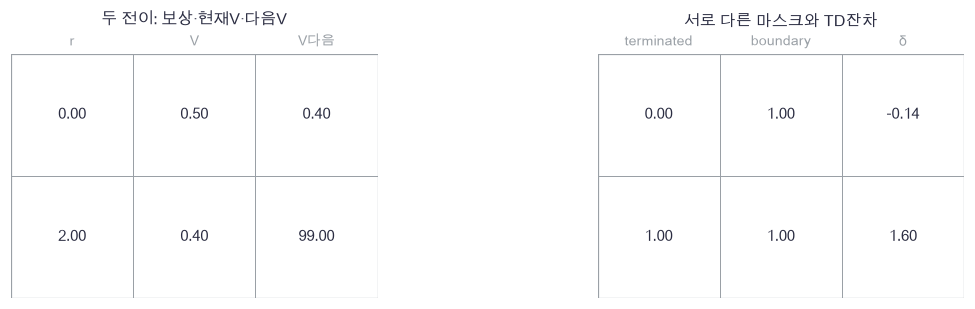

In [10]:
plot_gae_masks(boundary_rewards, boundary_values, boundary_next, terminal_mask, boundary_mask, boundary_delta)

🔍 **확인** · 수집 제한의 δ는0+.9×.4−.5=−.14입니다. 진짜 종료의 δ는2−.4=1.6이고 99가 사라집니다. 첫 행은 boundary=1이므로 둘째 조각의1.6을 advantage에 더하지 않습니다.

In [11]:
def gae_advantages(rewards,values,next_values,terminated,boundary,gamma=0.9,lam=0.95):
    """배치 경로:(B,T)의 TD잔차·GAE. terminal은bootstrap, boundary는다음잔차연결만 차단합니다."""
    delta = rewards+gamma*(1-terminated.astype(float))*next_values-values
    advantages = np.zeros_like(delta)
    running = np.zeros(len(delta))
    for time in reversed(range(delta.shape[1])):
        running = delta[:,time]+gamma*lam*(1-boundary[:,time].astype(float))*running
        advantages[:,time] = running
    return delta,advantages

In [12]:
# 쓰는 것: gamma (위 절의 정의·실행 셀)
delta,advantage = gae_advantages(boundary_rewards[None,:],boundary_values[None,:],boundary_next[None,:],terminal_mask[None,:],boundary_mask[None,:],gamma,1.)
np.testing.assert_allclose(delta,[[-.14,1.6]])  # 검산:수집제한bootstrap유지·종료99차단
np.testing.assert_allclose(advantage,delta)  # 검산:모든조각의boundary가다음잔차연결차단
changed_rewards = boundary_rewards.copy()
changed_rewards[1] = 1000.
changed_advantage = gae_advantages(changed_rewards[None,:],boundary_values[None,:],boundary_next[None,:],terminal_mask[None,:],boundary_mask[None,:],gamma,1.)[1]
np.testing.assert_allclose(changed_advantage[0,0],advantage[0,0])  # 검산:다른경로보상을바꿔도앞조각불변
print('두 마스크·실제 마지막 상태 bootstrap·경로 누출 차단 통과')

두 마스크·실제 마지막 상태 bootstrap·경로 누출 차단 통과


### ✏️ 연습 2 · TD잔차의 종료 처리

수집 경계가 아닌 실제 terminated로 다음 가치를 차단하세요.

In [13]:
def exercise_delta(reward, value, next_value, terminated, gamma):
    """TD잔차의 종료 처리의 핵심 식을 완성합니다."""
    raise NotImplementedError
    return delta

In [14]:
def check_delta(fn):
    """작은 독립 손계산으로 핵심 식을 검사합니다."""
    np.testing.assert_allclose(fn(2.,.4,99.,True,.9),1.6)  # 검산:종료다음값99차단
    print('TD잔차 통과')

run_check(check_delta,exercise_delta,hint='현재 value는 여전히 뺍니다.')

☐ exercise_delta: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: 현재 value는 여전히 뺍니다.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
delta = reward + gamma * (1 - float(terminated)) * next_value - value
```

</details>

## 🔑 3. GAE는 여러 TD잔차를 할인해 연결합니다

**이 절에서 가져갈 것:** λ는 잔차를 이어 붙이는 길이를 조절하며, critic의 오차가 타깃에 들어오는 정도도 바꿉니다.

이번에는 첫 전이에서 끊지 않고 0→위험1→종료3까지 실제 같은 경로를 모았습니다. 보상은 `[0,2]`, 이전 V는 `[.5,.4]`, TD잔차는 `[−.14,1.6]`입니다.

> **용어**
>
> - **GAE(generalized advantage estimation)**는 $\delta_t+(\gamma\lambda)\delta_{t+1}+\cdots$처럼 여러 TD잔차를 섞는 advantage 추정입니다. 경계를 넘지 않습니다.
> - **λ-return critic 타깃**은 $\widehat R_t^\lambda=V_{old}(s_t)+\widehat A_t$입니다. old V까지 포함해 타깃을 먼저 고정한 뒤 critic을 회귀합니다.

완료 경로에서 λ=0은 한 단계 TD, λ=1은 $G_t-V_{old}(s_t)$입니다. 수집 제한이라면 λ=1에도 마지막 다음 V가 남습니다. λ가 작을수록 항상 MSE가 작거나 학습이 좋다는 보장은 없습니다.

같은 고정 정책의4개 경로를 전부 열거해 $E[\hat g]$와 정확한 $\nabla J$를 비교합니다. 여기서
$$\hat g=\sum_t\gamma^t\widehat A_t\nabla\log\pi(a_t|s_t).$$
분산은 경로별 기울기 벡터의 $E[\|\hat g-E\hat g\|_2^2]$입니다. 표본 평균의 SE나 학습 seed SD와 다릅니다.

> **코드** · `np.column_stack`은 배열을 열로 붙입니다. `ravel()`은 배치·시간 축을 행 순서로 펼칩니다. `np.tile([False,True],(B,1))`는 B개의 완료 두 전이 경로에 같은 종료 표시를 만듭니다.

> **코드** · `p[:,None,None]`는 경로 확률을 기울기의 상태·행동 축에 곱하도록 축을 추가합니다. `np.linalg.norm(M)`은 행렬 원소 제곱합의 제곱근입니다. 분산 계산에서는 경로·상태·행동을 모두 합해 한 숫자를 만듭니다.

In [15]:
# 쓰는 것: gamma (위 절의 정의·실행 셀)
lambda_examples = np.array([0.,.5,1.])
gae_coefficients = np.column_stack([np.ones(3),gamma*lambda_examples])
gae_examples = np.column_stack([-.14+gamma*lambda_examples*1.6,np.full(3,1.6)])
return_examples = gae_examples+np.array([.5,.4])

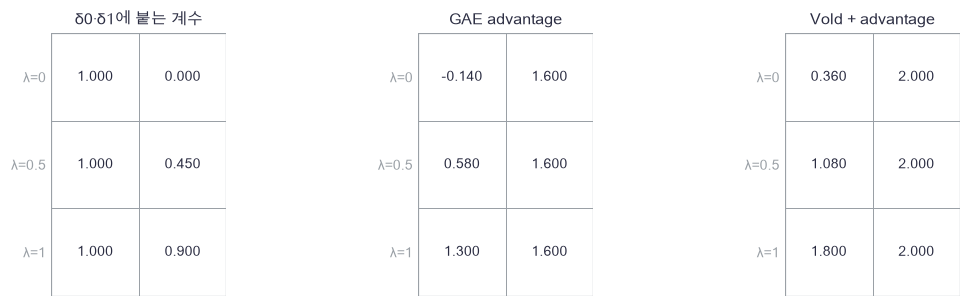

In [16]:
plot_gae_mixture(lambda_examples, gae_coefficients, gae_examples, return_examples)

🔍 **확인** · λ=1의 critic 타깃은 완료 경로의 MC return `[1.8,2]`가 됩니다. λ=0의 시작 타깃은 아직 부정확한 다음 V를 붙인 .36입니다. 다음 표에서는 정확한 critic과 일부러 틀린 critic을 구분해 기울기의 기대값과 분산을 계산합니다.

In [17]:
def enumerate_ac_paths(theta):
    """4개 완전 경로를 확률·상태·행동·보상 순서로 반환합니다. 경로 배열:(4,2)."""
    # 쓰는 것: ac_policy (위 절의 정의·실행 셀)
    policy,log_probabilities = ac_policy(theta,np.eye(3))
    states = np.array([[0,2],[0,2],[0,1],[0,1]])
    actions = np.array([[0,0],[0,1],[1,0],[1,1]])
    rewards = np.array([[0.,.7],[0.,.7],[0.,2.],[0.,-14.]])
    probabilities = policy[states,actions].prod(axis=1)
    return probabilities,states,actions,rewards

In [18]:
def prepare_ac_targets(states,rewards,critic,gamma=0.9,lam=0.95):
    """완료한 두 전이 경로의 이전 critic을 고정해 GAE·λ return을 만듭니다. 반환:(B,2) 두 배열."""
    # 쓰는 것: gae_advantages (위 절의 정의·실행 셀)
    values = critic[states].copy()
    next_values = np.column_stack([critic[states[:,1]],np.zeros(len(states))])
    terminated = np.tile(np.array([False,True]),(len(states),1))
    delta,advantages = gae_advantages(rewards,values,next_values,terminated,terminated,gamma,lam)
    returns = values+advantages
    return advantages,returns

In [19]:
def expected_gae_statistics(theta,critic,lam,gamma=0.9):
    """4경로 전수열거의 정책기울기 기대·정확미분과의편향norm·경로기울기분산trace를 반환합니다."""
    # 쓰는 것: ac_exact, ac_policy (위 절의 정의·실행 셀)
    probabilities,states,actions,rewards = enumerate_ac_paths(theta)
    policy,log_probabilities = ac_policy(theta,np.eye(3))
    advantages,returns = prepare_ac_targets(states,rewards,critic,gamma,lam)
    path_gradients = np.zeros((4,3,2))
    for path in range(4):
        for time in range(2):
            state,action = states[path,time],actions[path,time]
            score = np.eye(2)[action]-policy[state]
            path_gradients[path,state] += gamma**time*advantages[path,time]*score
    mean = np.sum(probabilities[:,None,None]*path_gradients,axis=0)
    exact_gradient = ac_exact(theta,gamma)[1]
    bias = np.linalg.norm(mean-exact_gradient)
    variance = np.sum(probabilities[:,None,None]*(path_gradients-mean)**2)
    return mean,float(bias),float(variance)

In [20]:
# 쓰는 것: exact_critic, example_theta, return_examples (위 절의 정의·실행 셀)
path_probabilities,path_states,path_actions,path_rewards = enumerate_ac_paths(example_theta)
np.testing.assert_allclose(path_probabilities.sum(),1.)  # 검산:가능한4경로확률합1
wrong_critic = np.array([.2,-1.,.1])
stat_rows,stat_labels = [],[]
for critic_name,critic_values in [('정확V',exact_critic),('틀린V',wrong_critic)]:
    for lam in [0.,.95,1.]:
        mean_gradient,bias,variance = expected_gae_statistics(example_theta,critic_values,lam)
        stat_rows.append([bias,variance])
        stat_labels.append(f'{critic_name} λ={lam:g}')
        if critic_name=='정확V' or lam==1.:
            np.testing.assert_allclose(mean_gradient,exact_gradient,atol=1e-13)  # 검산:정확V또는완료MC의정책기울기기대값항등식
statistics = np.array(stat_rows)
for lam in [0.,1.]:
    complete_advantage,complete_return = prepare_ac_targets(np.array([[0,1]]),np.array([[0.,2.]]),np.array([.5,.4,.7]),lam=lam)
    np.testing.assert_allclose(complete_return[0],return_examples[int(lam)*2])  # 검산:GAE양끝직접계산
print('4경로 기울기 기대값·λ 양끝 통과')

4경로 기울기 기대값·λ 양끝 통과


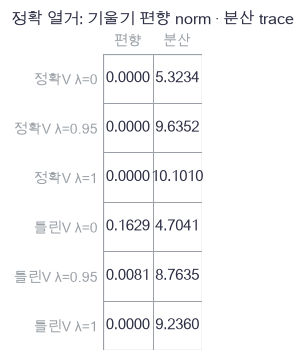

In [21]:
plot_gae_bias_variance(statistics, stat_labels)

🔍 **확인** · 정확 V일 때 기대 기울기의 편향은 수치 오차 수준입니다. 틀린 V를 bootstrap하는 짧은 타깃에는 편향이 생길 수 있습니다. 완료 MC인 λ=1에서는 action에 무관한 이전 baseline을 빼도 기대 기울기는 유지됩니다. 이 항등식은 앞으로의 유한 학습에서 어느 λ가 이길지 결정하지 않습니다.

### ✏️ 연습 3 · 한 단계 GAE 재귀

boundary가 아니면 다음 advantage를 할인해 더하세요.

In [22]:
def exercise_gae(delta, next_advantage, gamma, lam, boundary):
    """한 단계 GAE 재귀의 핵심 식을 완성합니다."""
    raise NotImplementedError
    return advantage

In [23]:
def check_gae(fn):
    """작은 독립 손계산으로 핵심 식을 검사합니다."""
    np.testing.assert_allclose(fn(-.14,1.6,.9,.5,False),.58)  # 검산:−.14+.45×1.6
    print('GAE 재귀 통과')

run_check(check_gae,exercise_gae,hint='종료 마스크는 이미 delta 계산에서 썼습니다.')

☐ exercise_gae: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: 종료 마스크는 이미 delta 계산에서 썼습니다.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
advantage = delta + gamma * lam * (1 - float(boundary)) * next_advantage
```

</details>

## 🔑 4. actor와 critic의 고정 타깃 손실을 따로 미분합니다

**이 절에서 가져갈 것:** actor는 episode 평균, critic은 transition 평균으로 정규화하며 서로의 파라미터를 갱신하지 않습니다.

한 배치로 advantage와 return을 먼저 만들고 고정했습니다. 그다음 actor는 좋은 행동의 log확률을 높이고 critic은 return을 예측합니다. 같은 배치로 critic을 먼저 재학습한 값을 actor baseline으로 다시 넣지 않습니다.

$$L_\pi=-\frac1B\sum_{i,t}\gamma^t\widehat A_{i,t}\log\pi_\theta(a_{i,t}|s_{i,t}),\qquad
L_V=\frac1{2N}\sum_j(X_jw-\widehat R_j^\lambda)^2.$$

N=2B는 전이 수입니다. J는 시작 시점 할인 return이므로 actor의 γ^t를 빼지 않습니다. critic은 전이 평균의 회귀 목적이며 actor와 분모가 다릅니다.

$$d\ell_j=\frac{\gamma^{t_j}\widehat A_j}{B}(\pi_j-onehot(a_j)),\quad d\theta=X^Td\ell,$$
$$dw=X^T(V-\widehat R)/N,\quad dX_\pi=d\ell\theta^T,\quad dX_V=((V-\widehat R)/N)w^T.$$

> **용어** · **고정 타깃의 미분**은 이미 계산한 A·Rλ·행동·할인계수를 상수로 보고 현재 actor/critic만 미분하는 것입니다. 아래 중심차분도 이 같은 목적을 검사합니다. rollout의 행동 표본이나 GAE를 재계산하는 미분이 아닙니다.

> **코드** · `np.ndindex(array.shape)`는 배열의 모든 위치를 순회합니다. 중심차분은 한 원소를 더하고 뺀 뒤 반드시 원래 값으로 복원합니다. 반환값의 입력 미분 두 개는 각각 actor 목적과 critic 목적에서 왔습니다.

In [24]:
# 쓰는 것: example_policy (위 절의 정의·실행 셀)
loss_states = np.array([0,1])
loss_actions = np.array([1,0])
loss_x = np.eye(3)[loss_states]
loss_critic = np.array([.5,.4,.7])
fixed_advantage = np.array([1.3,1.6])
fixed_return = np.array([1.8,2.0])
loss_discounts = np.array([1.,.9])
manual_dlogits = (loss_discounts*fixed_advantage)[:,None]*(example_policy[loss_states]-np.eye(2)[loss_actions])
manual_actor_gradient = loss_x.T@manual_dlogits
manual_critic_gradient = loss_x.T@((loss_x@loss_critic-fixed_return)/2)

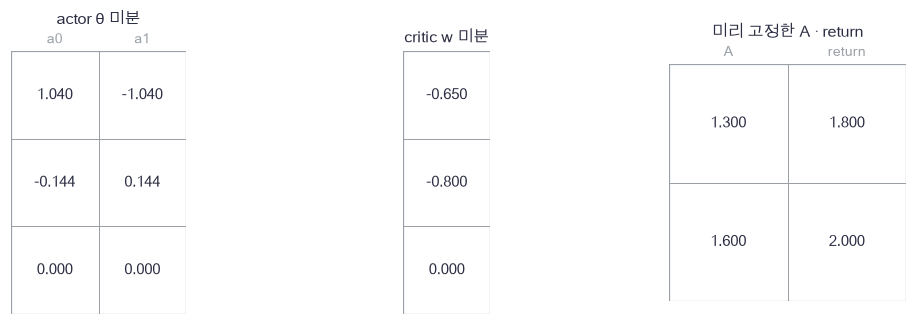

In [25]:
plot_ac_gradients(manual_actor_gradient, manual_critic_gradient, np.column_stack([fixed_advantage,fixed_return]))

🔍 **확인** · actor 미분은 각 상태의 두 행동 확률을 반대 방향으로 움직입니다. critic 미분은 값 예측 오차를 줄입니다. 두 모델 사이에는 타깃을 만드는 연결이 있지만 이 업데이트의 미분 그래프는 분리되어 있습니다.

In [26]:
def ac_losses(theta,critic,x,actions,discounts,advantages,returns,episodes):
    """고정 A·return에서 actor는episode평균, critic은transition평균으로 손실·두모델·입력 미분을 계산합니다."""
    # 쓰는 것: ac_policy (위 절의 정의·실행 셀)
    probabilities,log_probabilities = ac_policy(theta,x)
    rows = np.arange(len(x))
    coefficients = discounts*advantages/episodes
    actor_loss = -np.sum(coefficients*log_probabilities[rows,actions])
    d_logits = coefficients[:,None]*(probabilities-np.eye(2)[actions])
    value_residual = x@critic-returns
    critic_loss = 0.5*np.mean(value_residual**2)
    d_values = value_residual/len(x)
    return (float(actor_loss),float(critic_loss),x.T@d_logits,x.T@d_values,
            d_logits@theta.T,d_values[:,None]*critic[None,:])

In [27]:
def check_ac_gradients(theta,critic,x,actions,discounts,advantages,returns,episodes,step=1e-5):
    """고정 타깃 Lactor+.5Lcritic의 전체 actor·critic·입력 중심차분입니다."""
    # 1. 따로 계산한 두 모델의 미분을 하나의 검산용 합성 목적과 대조합니다.
    result = ac_losses(theta,critic,x,actions,discounts,advantages,returns,episodes)
    analytic = {'theta':result[2],'critic':0.5*result[3],'X':result[4]+0.5*result[5]}
    errors = {}
    for name,array in [('theta',theta),('critic',critic),('X',x)]:
        numeric = np.zeros_like(array)
        # 2. 타깃·advantage·행동·할인 계수는 그대로 두고 변수 하나만 움직입니다.
        for index in np.ndindex(array.shape):
            original = array[index]
            array[index] = original+step
            plus = ac_losses(theta,critic,x,actions,discounts,advantages,returns,episodes)
            array[index] = original-step
            minus = ac_losses(theta,critic,x,actions,discounts,advantages,returns,episodes)
            array[index] = original
            numeric[index] = (plus[0]+0.5*plus[1]-minus[0]-0.5*minus[1])/(2*step)
        errors[name] = np.max(np.abs(numeric-analytic[name]))
    return errors

In [28]:
# 쓰는 것: example_theta, fixed_advantage, fixed_return, loss_actions, loss_critic, loss_discounts, loss_x, manual_actor_gradient, manual_critic_gradient (위 절의 정의·실행 셀)
loss_result = ac_losses(example_theta,loss_critic,loss_x,loss_actions,loss_discounts,fixed_advantage,fixed_return,1)
np.testing.assert_allclose(loss_result[2],manual_actor_gradient)  # 검산:actor수식미분=핵심함수
np.testing.assert_allclose(loss_result[3],manual_critic_gradient)  # 검산:critic전이평균미분
changed_critic = ac_losses(example_theta,loss_critic+3.,loss_x,loss_actions,loss_discounts,fixed_advantage,fixed_return,1)
np.testing.assert_allclose(changed_critic[2],loss_result[2])  # 검산:고정A에서critic변경은actor미분에영향없음
changed_actor = ac_losses(example_theta+.3*np.eye(3,2),loss_critic,loss_x,loss_actions,loss_discounts,fixed_advantage,fixed_return,1)
np.testing.assert_allclose(changed_actor[3],loss_result[3])  # 검산:고정return에서actor변경은critic미분에영향없음
gradient_rng = np.random.default_rng(57001)
gradient_theta = gradient_rng.normal(size=(3,2))*.2
gradient_critic = gradient_rng.normal(size=3)*.2
gradient_x = gradient_rng.normal(size=(3,3))
gradient_errors = check_ac_gradients(gradient_theta,gradient_critic,gradient_x,np.array([0,1,0]),np.array([1.,.9,1.]),np.array([.3,-.2,.7]),np.array([1.,.5,-.4]),2)
assert max(gradient_errors.values())<1e-7, 'actor6개·critic3개·입력전체의중심차분이맞아야합니다'
print('두 모델 분리·전체 중심차분:',gradient_errors)

두 모델 분리·전체 중심차분: {'theta': np.float64(6.48087139509812e-12), 'critic': np.float64(9.78092606906955e-13), 'X': np.float64(3.710778212484556e-12)}


### ✏️ 연습 4 · critic 회귀 미분

전이 수 N으로 나눈 선형 critic의 dw를 구하세요.

In [29]:
def exercise_critic_gradient(x, values, returns):
    """critic 회귀 미분의 핵심 식을 완성합니다."""
    raise NotImplementedError
    return gradient

In [30]:
def check_critic_gradient(fn):
    """작은 독립 손계산으로 핵심 식을 검사합니다."""
    np.testing.assert_allclose(fn(np.eye(2),np.array([.5,.4]),np.array([1.8,2.])),[-.65,-.8])  # 검산:전이평균미분
    print('critic 미분 통과')

run_check(check_critic_gradient,exercise_critic_gradient,hint='actor의 episode 분모와 구분합니다.')

☐ exercise_critic_gradient: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: actor의 episode 분모와 구분합니다.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
gradient = x.T @ (values - returns) / len(x)
```

</details>

## 🔑 5. 새 rollout마다 두 모델을 실제로 갱신합니다

**이 절에서 가져갈 것:** 같은 예산으로 λ를 바꾸되 모든 학습 실행과 독립 평가를 남깁니다.

λ=0·.95·1, 각3개 독립 seed를 결과 전에 정합니다. 매 갱신마다 현재 확률정책으로64개의 새 완료 경로를 모으고, 이전 critic으로 A·Rλ를 고정한 뒤 actor1회·critic1회 SGD를 합니다. 총300번, 각 실행19,200개 episode·38,400개 전이입니다. actor 학습률.05·critic 학습률.2를 고정하며 replay와 advantage 정규화는 쓰지 않습니다.

정확 J와 현재 정책의 정확 V는 평가용입니다. 실제 업데이트에는 수집한 경로만 사용합니다. actor는 θ, critic은 w의 별도 배열이라 critic loss가 actor를 바꾸지 않습니다. 마지막 평가는 greedy 정책으로 바꾸지 않고 **학습한 확률정책 그대로** 별도의2,048개 경로를 수집합니다.

> **코드** · `np.where(condition,a,b)`는 조건이 참인 위치에 a, 나머지에 b를 넣습니다. `states.ravel()`을 one-hot으로 바꾸면 `(B,2)` 상태를 `(2B,3)` 입력 행으로 펼칩니다. `np.stack`은 동일한 모양의 학습 기록을 새 seed 축으로 쌓습니다.

In [31]:
LAMBDAS = [0.,.95,1.]
REPEATS,UPDATES,BATCH_SIZE = 3,300,64
protocol_settings = np.array([[REPEATS],[UPDATES],[BATCH_SIZE],[.05],[.2]])
protocol_values = np.array([.5,.4])
protocol_returns = np.array([1.8,2.])
protocol_updated = protocol_values-.2*(protocol_values-protocol_returns)/2
protocol_sequence = np.column_stack([protocol_values,protocol_returns,protocol_updated])

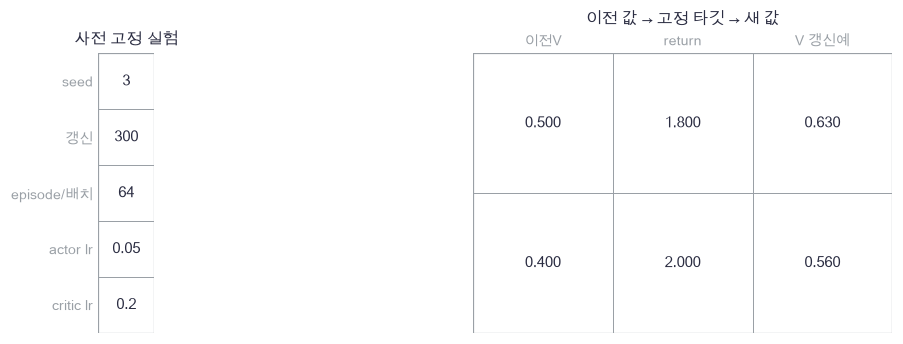

In [32]:
plot_ac_protocol(protocol_settings, protocol_sequence)

🔍 **확인** · 그림은 critic 두 값에 대한 한 회귀 갱신의 예시입니다. 실제 실험에서는 여러 경로의 방문 상태마다 미분을 더합니다. 이전 critic으로 만든 타깃을 고정하므로 actor와 critic의 갱신 순서가 이 고정 배열을 바꾸지 않습니다.

In [33]:
def sample_ac_paths(theta,count,rng):
    """동결한 현재 정책으로 두 전이 경로를 실제 수집합니다. 상태·행동·보상:(B,2)."""
    # 쓰는 것: ac_policy (위 절의 정의·실행 셀)
    policy,log_probabilities = ac_policy(theta,np.eye(3))
    uniforms = rng.random((count,2))
    first = (uniforms[:,0]>=policy[0,0]).astype(int)
    second_state = np.where(first==0,2,1)
    second = (uniforms[:,1]>=policy[second_state,0]).astype(int)
    states = np.column_stack([np.zeros(count,dtype=int),second_state])
    actions = np.column_stack([first,second])
    reward_table = np.array([[0.,0.],[2.,-14.],[.7,.7]])
    return states,actions,reward_table[states,actions]

In [34]:
def train_actor_critic(seed,lam=0.95,updates=300,batch_size=64):
    """각갱신마다새경로→이전critic고정GAE→actor1회·critic1회 SGD. 실제학습·정확평가 기록을 반환합니다."""
    # 쓰는 것: ac_exact, ac_losses, prepare_ac_targets (위 절의 정의·실행 셀)
    # 1. actor와critic은 별도 배열이며 같은0초기값에서 출발합니다.
    theta,critic = np.zeros((3,2)),np.zeros(3)
    rng = np.random.default_rng(seed)
    records,observed = [],[]
    for update in range(updates+1):
        if update%10==0:
            exact_value,exact_gradient,truth = ac_exact(theta)
            records.append([update,exact_value,np.sqrt(np.mean((critic-truth)**2))])
        if update==updates:
            break
        # 2. 같은배치로critic을먼저재학습하지않고, 이전값으로모든타깃을먼저고정합니다.
        states,actions,rewards = sample_ac_paths(theta,batch_size,rng)
        advantages,returns = prepare_ac_targets(states,rewards,critic,lam=lam)
        x = np.eye(3)[states.ravel()]
        discounts = np.tile(np.array([1.0,0.9]),batch_size)
        losses = ac_losses(theta,critic,x,actions.ravel(),discounts,advantages.ravel(),returns.ravel(),batch_size)
        # 3. 공유파라미터없이각손실의미분만자기모델에적용합니다.
        theta -= 0.05*losses[2]
        critic -= 0.2*losses[3]
        observed.append(np.mean(rewards[:,0]+0.9*rewards[:,1]))
    return theta,critic,np.array(records),np.array(observed)

In [35]:
# 쓰는 것: BATCH_SIZE, LAMBDAS, REPEATS, UPDATES (위 절의 정의·실행 셀)
histories,final_actors,final_critics,observed_returns = [],[],[],[]
for lam in LAMBDAS:
    lambda_histories,actors,critics,observed = [],[],[],[]
    for repeat in range(REPEATS):
        theta,critic,history,returns = train_actor_critic(57100+repeat,lam,UPDATES,BATCH_SIZE)
        lambda_histories.append(history)
        actors.append(theta)
        critics.append(critic)
        observed.append(returns)
    histories.append(np.stack(lambda_histories))
    final_actors.append(np.stack(actors))
    final_critics.append(np.stack(critics))
    observed_returns.append(np.stack(observed))
histories = np.stack(histories)
final_actors = np.stack(final_actors)
observed_returns = np.stack(observed_returns)
print('실제 학습:3λ×3seed×300갱신×64episode · 각episode2전이')

실제 학습:3λ×3seed×300갱신×64episode · 각episode2전이


In [36]:
update_axis = histories[0,0,:,0]
exact_values = histories[:,:,:,1]
critic_errors = histories[:,:,:,2]
mean_values,mean_errors = exact_values.mean(axis=1),critic_errors.mean(axis=1)
names = ['λ=0','λ=.95','λ=1']

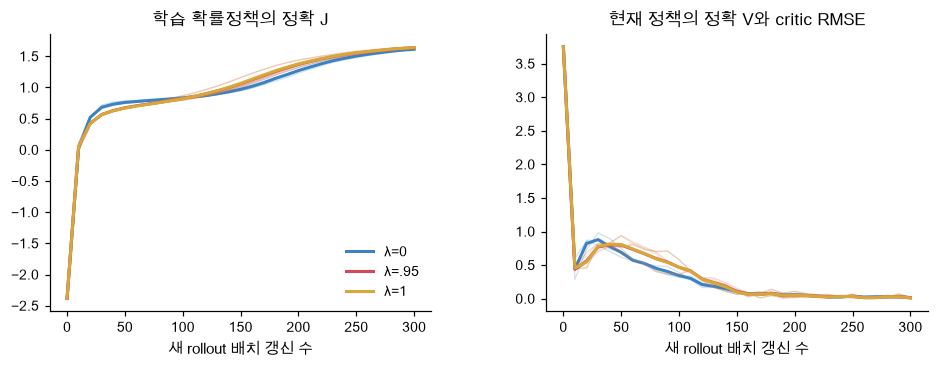

In [37]:
plot_ac_learning(update_axis, exact_values, critic_errors, mean_values, mean_errors, names)

🔍 **확인** · 얇은 선은 독립 학습 seed 각각이고 굵은 선은3개 평균입니다. 정확 V도 정책이 바뀔 때 같이 바뀌므로 critic RMSE는 움직이는 평가 대상을 추적합니다. 이 한 환경의 유한 예산에서 관측한 순위를 GAE λ의 보편적 순위로 해석하지 않습니다.

In [38]:
# 쓰는 것: LAMBDAS, ac_exact, gamma, sample_ac_paths (위 절의 정의·실행 셀)
evaluation = np.zeros((3,3))
for index,lam in enumerate(LAMBDAS):
    states,actions,rewards = sample_ac_paths(final_actors[index,0],2048,np.random.default_rng(57999))
    returns = rewards[:,0]+gamma*rewards[:,1]
    evaluation[index] = [returns.mean(),returns.std(ddof=1)/np.sqrt(2048),ac_exact(final_actors[index,0])[0]]
    print(names[index],'각seed 최종J:',np.round(exact_values[index,:,-1],4),'학습중평균return:',np.round(observed_returns[index].mean(axis=1),4))
assert np.isfinite(histories).all(), '모든학습기록은유한해야합니다'
print('평가표 열: 독립경로 평균 / 조건부MC SE / 정확J')

λ=0 각seed 최종J: [1.6046 1.6128 1.622 ] 학습중평균return: [0.9805 0.9877 1.0282]
λ=.95 각seed 최종J: [1.6263 1.6367 1.6491] 학습중평균return: [0.9942 0.9999 1.0808]
λ=1 각seed 최종J: [1.6293 1.6363 1.6504] 학습중평균return: [1.0088 1.0013 1.0794]
평가표 열: 독립경로 평균 / 조건부MC SE / 정확J


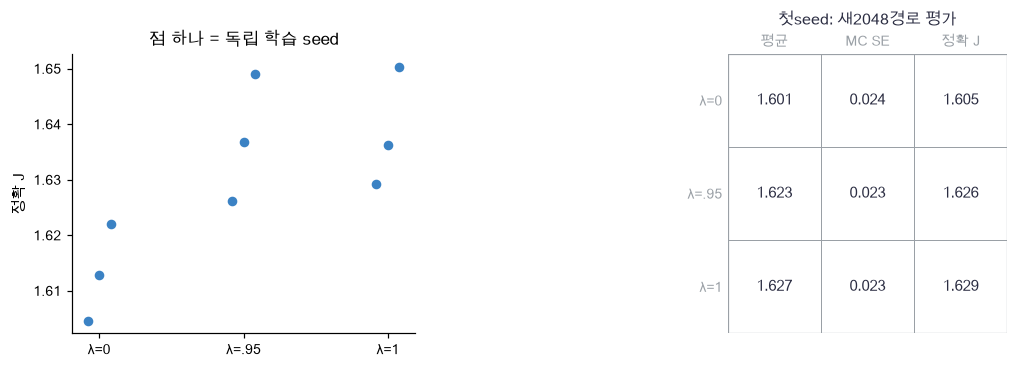

In [39]:
plot_ac_final(names, exact_values[:,:,-1], evaluation)

🔍 **확인** · 새 경로의 SE는 **고정한 한 학습 정책**을 평가하는 표본 평균의 불확실성입니다. 세 학습 seed 사이의 차이와 다릅니다. 같은 평가 난수 seed로 방법을 비교했지만 각 방법 안의2,048개 경로는 독립 표본입니다. 최적1.8과의 남은 차이도 그대로 읽습니다.

### ✏️ 연습 5 · 두 모델의 별도 SGD

actor에는 actor gradient, critic에는 critic gradient를 적용하세요.

In [40]:
def exercise_separate_update(theta, critic, actor_gradient, critic_gradient, actor_lr, critic_lr):
    """두 모델의 별도 SGD의 핵심 식을 완성합니다."""
    raise NotImplementedError
    return new_theta, new_critic

In [41]:
def check_separate_update(fn):
    """작은 독립 손계산으로 핵심 식을 검사합니다."""
    a,c=fn(np.array([1.]),np.array([2.]),np.array([.5]),np.array([-.5]),.1,.2)
    np.testing.assert_allclose(np.concatenate([a,c]),[.95,2.1])  # 검산:서로다른gradient와학습률
    print('두 모델 별도 갱신 통과')

run_check(check_separate_update,exercise_separate_update,hint='critic gradient를 actor에 더하지 않습니다.')

☐ exercise_separate_update: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: critic gradient를 actor에 더하지 않습니다.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
new_theta = theta - actor_lr * actor_gradient
new_critic = critic - critic_lr * critic_gradient
```

</details>

## ✏️ 전체 연결 연습 A–D

할인·고정 return·경계·분모를 다시 확인합니다.

### ✏️ 연습 A · 시작 목적의 시점 할인

현재 시점 기준 advantage에 시작 시점 할인계수를 곱하세요.

In [42]:
def exercise_discount(advantage, time, gamma):
    """시작 목적의 시점 할인의 핵심 식을 완성합니다."""
    raise NotImplementedError
    return weight

In [43]:
def check_discount(fn):
    """작은 독립 손계산으로 핵심 식을 검사합니다."""
    np.testing.assert_allclose(fn(2.,1,.9),1.8)  # 검산:두번째전이의시작기준할인
    print('actor 시점 할인 통과')

run_check(check_discount,exercise_discount,hint='GAE 안의 할인과 별도로 gamma의 t제곱입니다.')

☐ exercise_discount: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: GAE 안의 할인과 별도로 gamma의 t제곱입니다.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
weight = gamma**time * advantage
```

</details>

### ✏️ 연습 B · critic의 고정 λ 타깃

이전 V와 advantage를 합하세요.

In [44]:
def exercise_return_target(old_values, advantages):
    """critic의 고정 λ 타깃의 핵심 식을 완성합니다."""
    raise NotImplementedError
    return returns

In [45]:
def check_return_target(fn):
    """작은 독립 손계산으로 핵심 식을 검사합니다."""
    np.testing.assert_allclose(fn(np.array([.5,.4]),np.array([1.3,1.6])),[1.8,2.])  # 검산:완료λ1은MCreturn
    print('critic 타깃 통과')

run_check(check_return_target,exercise_return_target,hint='갱신한 새 critic 값으로 다시 만들지 않습니다.')

☐ exercise_return_target: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: 갱신한 새 critic 값으로 다시 만들지 않습니다.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
returns = old_values + advantages
```

</details>

### ✏️ 연습 C · 경계를 넘지 않습니다

boundary이면 next_advantage의 크기와 관계없이 delta만 반환하세요.

In [46]:
def exercise_boundary(delta, next_advantage, boundary):
    """경계를 넘지 않습니다의 핵심 식을 완성합니다."""
    raise NotImplementedError
    return result

In [47]:
def check_boundary(fn):
    """작은 독립 손계산으로 핵심 식을 검사합니다."""
    np.testing.assert_allclose(fn(-.14,1000.,True),-.14)  # 검산:다른episode의미래차단
    print('경로 경계 통과')

run_check(check_boundary,exercise_boundary,hint='이 문제에서는 gamma·lambda가 이미 다음 항에 반영됐습니다.')

☐ exercise_boundary: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: 이 문제에서는 gamma·lambda가 이미 다음 항에 반영됐습니다.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
result = delta + (1 - float(boundary)) * next_advantage
```

</details>

### ✏️ 연습 D · episode 평균 actor 손실

행에episode, 열에시간이 있습니다. 시간은합하고episode는평균하세요.

In [48]:
def exercise_normalization(weighted_logprob):
    """episode 평균 actor 손실의 핵심 식을 완성합니다."""
    raise NotImplementedError
    return loss

In [49]:
def check_normalization(fn):
    """작은 독립 손계산으로 핵심 식을 검사합니다."""
    np.testing.assert_allclose(fn(np.array([[-1.,-2.],[-3.,-4.]])),5.)  # 검산:−((−3)+(−7))/2
    print('actor episode 분모 통과')

run_check(check_normalization,exercise_normalization,hint='모든 원소를 그냥 mean하면 시간 길이만큼 달라집니다.')

☐ exercise_normalization: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: 모든 원소를 그냥 mean하면 시간 길이만큼 달라집니다.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
loss = -np.mean(np.sum(weighted_logprob, axis=1))
```

</details>

## ✏️ 준비도: 네 가지로 확인합니다

- **설명:** actor의 확률·critic의 값·advantage의 역할을 나누고, 왜 A를 고정한 채 미분하는지 말할 수 있나요?
- **수식:** λ=0과 λ=1의 완료 경로 타깃을 전개하고, 수집 제한에서 마지막 bootstrap이 남는 이유를 설명할 수 있나요?
- **구현:** terminated와 boundary를 나눠 다른 경로의 잔차가 새지 않게 하고 두 모델의 미분을 독립 검산할 수 있나요?
- **변형 검산:** critic을 일부러 틀리게 했을 때 λ별 경로 기울기의 정확 기대값·분산을 열거하고 실제 학습과 구분할 수 있나요?

## 📎 참고: 원자료와 다음 연결

- Schulman 외, [High-Dimensional Continuous Control Using Generalized Advantage Estimation](https://arxiv.org/abs/1506.02438): TD잔차를 여러 길이로 섞어 편향·분산을 다루는 GAE 원자료입니다. 여기서는 정확 열거가 가능한 표 기반 선형 모델을 씁니다.
- [Spinning Up 정책 최적화 설명](https://spinningup.openai.com/en/latest/spinningup/rl_intro3.html): trajectory 확률, reward-to-go, state baseline의 미분 연결을 읽을 수 있습니다. 본문은 시작 기준 할인 목적의 γ^t를 명시합니다.
- 58 PPO에서는 한 rollout 배치를 여러 번 재사용할 때 필요한 old log확률·확률비·clip을 연결합니다. 이번에는 새 배치마다 actor를 한 번 갱신하므로 그 보정이 필요하지 않습니다. [전체 경로](../../docs/CURRICULUM.md)